In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
warnings.filterwarnings("ignore")

In [2]:
SEED = 42
DATA_DIR = "data_sets/" 
OUT_DIR   = os.path.join(DATA_DIR, "outputs")
os.makedirs(OUT_DIR, exist_ok=True)
print("Files found:", os.listdir(DATA_DIR))

tas_long = pd.read_csv(f"{DATA_DIR}/climate_with_country_names.csv")        
clim2    = pd.read_csv(f"{DATA_DIR}/second_climate_country (1).csv")        
wb_year  = pd.read_csv(f"{DATA_DIR}/world_bank_agriculture_annual.csv")     
wb_avg   = pd.read_csv(f"{DATA_DIR}/world_bank_agriculture_data.csv") 

Files found: ['climate_with_country_names.csv', 'world_bank_agriculture_data.csv', 'world_bank_agriculture_annual.csv', 'second_climate_country (1).csv', 'outputs']


## Feature engineering: climate

In [3]:
tas_long["year"] = tas_long["date"].str[:4].astype(int)
def tas_features(g):
    g = g.dropna(subset=["tas"]).set_index("year")["tas"]
    base   = g.loc[1951:1980].mean()
    recent = g.loc[2001:2020]
    if len(recent) < 10 or len(g.loc[1951:1980]) < 10:               # country without enough data
        return pd.Series({"temp_mean": np.nan, "temp_anomaly": np.nan, "temp_trend": np.nan})
    trend  = np.polyfit(recent.index, recent.values, 1)[0] * 10   # °C per decade
    return pd.Series({"temp_mean": recent.mean(),                 # average annual temperature
                      "temp_anomaly": recent.mean() - base,       # warming vs 1951-1980
                      "temp_trend": trend})
temp = tas_long.groupby("country_code").apply(tas_features)

In [4]:
clim2["year"] = clim2["date"].str[:4].astype(int)
clim2 = clim2[clim2.year.between(2001, 2020)]                     # same window as World Bank data
pr    = clim2[clim2.indicator == "pr"].groupby("country")["value"].agg(["mean", "std"])
pr    = pd.DataFrame({"precip_mean": pr["mean"], "precip_cv": pr["std"] / pr["mean"]})  # amount + variability
sp    = clim2[clim2.indicator == "spei12"].groupby("country")["value"].agg(
            drought_freq=lambda x: (x.dropna() < -1).mean(),       # share of years with SPEI-12 < -1
            spei_mean="mean")
climate = pr.join(sp)

### map names of the 2nd file to ISO codes (via the 1st file) & manual fixes for different spellings

In [5]:
name2code = tas_long.drop_duplicates("country_code").set_index("country_name")["country_code"].to_dict()
manual = {"Bolivia":"BOL","Iran":"IRN","Kosovo":"KSV","Laos":"LAO","Moldova":"MDA","North Korea":"PRK",
          "South Korea":"KOR","Syria":"SYR","Taiwan":"TWN","Tanzania":"TZA","Venezuela":"VEN","Vietnam":"VNM"}
name2code.update(manual)
climate["country_code"] = climate.index.map(name2code)
climate = climate.dropna(subset=["country_code"]).set_index("country_code")
names   = tas_long.drop_duplicates("country_code").set_index("country_code")["country_name"]


In [6]:
soc_cols = ["agriculture_gdp_percent", "rural_population_percent", "agricultural_land_percent"]
soc = wb_year.groupby("country_code")[soc_cols].mean()
fallback = wb_avg.set_index("country_code")[soc_cols]
soc = soc.fillna(fallback)   

### Merge Data sets

In [7]:
df = temp.join(climate, how="inner").join(soc, how="inner")        # inner join also drops WB regional aggregates
df.insert(0, "country", names.reindex(df.index))
print("Countries before cleaning:", len(df))
print("Missing values:\n", df.isna().sum()[lambda s: s > 0])
df = df.dropna()                                                   # remove countries with incomplete data
print("Countries used:", len(df))

features = ["temp_mean", "temp_anomaly", "precip_mean", "precip_cv", "drought_freq",
            "agriculture_gdp_percent", "rural_population_percent", "agricultural_land_percent"]


Countries before cleaning: 215
Missing values:
 drought_freq                  1
spei_mean                     1
agriculture_gdp_percent      12
agricultural_land_percent     6
dtype: int64
Countries used: 200


### Pre-processing

In [8]:
X = df[features].copy()
for c in ["precip_mean", "agriculture_gdp_percent"]:               # reduce right skew
    X[c] = np.log1p(X[c])
Xs = StandardScaler().fit_transform(X)


### Choose k : Silhouette + Davies-Bouldin (+ elbow) 


Model selection:
  k  inertia  km_sil  km_db  hc_sil  hc_db
 2 1250.687   0.217  1.746   0.209  1.859
 3 1031.120   0.243  1.490   0.227  1.515
 4  881.299   0.224  1.399   0.202  1.505
 5  769.917   0.227  1.343   0.157  1.491
 6  721.328   0.228  1.371   0.167  1.405
 7  678.757   0.203  1.382   0.168  1.465
 8  631.885   0.178  1.414   0.170  1.563


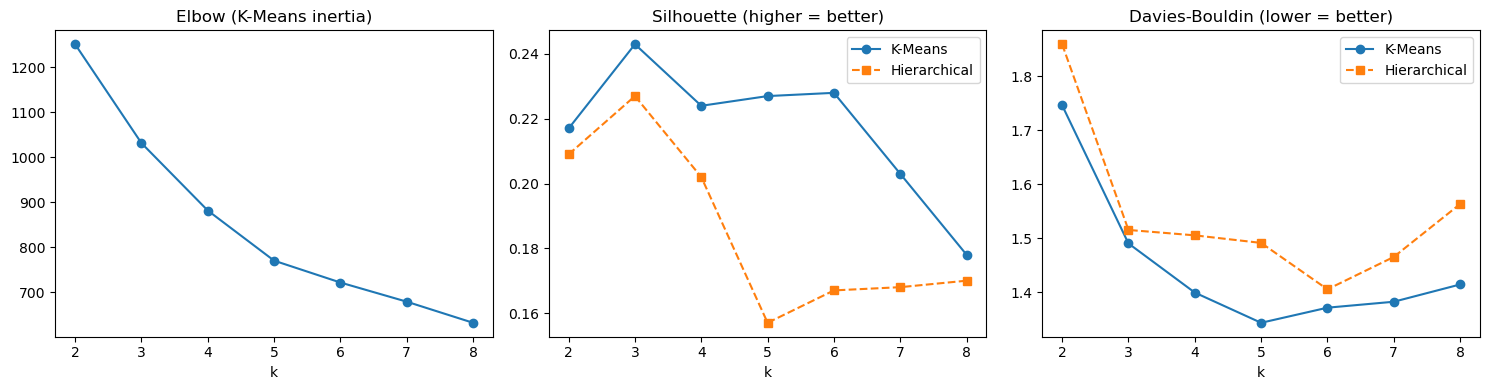

In [9]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Xs)
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(Xs)
    rows.append(dict(k=k, inertia=km.inertia_,
                     km_sil=silhouette_score(Xs, km.labels_), km_db=davies_bouldin_score(Xs, km.labels_),
                     hc_sil=silhouette_score(Xs, ag.labels_), hc_db=davies_bouldin_score(Xs, ag.labels_)))
res = pd.DataFrame(rows).round(3)
print("\nModel selection:\n", res.to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(res.k, res.inertia, "o-"); ax[0].set_title("Elbow (K-Means inertia)")
ax[1].plot(res.k, res.km_sil, "o-", label="K-Means"); ax[1].plot(res.k, res.hc_sil, "s--", label="Hierarchical")
ax[1].set_title("Silhouette (higher = better)"); ax[1].legend()
ax[2].plot(res.k, res.km_db, "o-", label="K-Means"); ax[2].plot(res.k, res.hc_db, "s--", label="Hierarchical")
ax[2].set_title("Davies-Bouldin (lower = better)"); ax[2].legend()
for a in ax: a.set_xlabel("k")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig1_model_selection.png", dpi=150); plt.show()


In [18]:
cand = res[res.k.between(3, 8)]
print(cand)
K = int(cand.loc[cand.km_sil.idxmax(), "k"])
print(f"\nSelected k = {K}")

   k   inertia  km_sil  km_db  hc_sil  hc_db
1  3  1031.120   0.243  1.490   0.227  1.515
2  4   881.299   0.224  1.399   0.202  1.505
3  5   769.917   0.227  1.343   0.157  1.491
4  6   721.328   0.228  1.371   0.167  1.405
5  7   678.757   0.203  1.382   0.168  1.465
6  8   631.885   0.178  1.414   0.170  1.563

Selected k = 3


### Final models

In [16]:
km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(Xs)
hc = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Xs)
df["cluster_kmeans"], df["cluster_hier"] = km.labels_, hc.labels_

summary = pd.DataFrame({
    "Silhouette":     [silhouette_score(Xs, km.labels_), silhouette_score(Xs, hc.labels_)],
    "Davies-Bouldin": [davies_bouldin_score(Xs, km.labels_), davies_bouldin_score(Xs, hc.labels_)]},
    index=["K-Means", "Hierarchical (Ward)"]).round(3)
print("\nFinal evaluation:\n", summary)
print("Agreement between the two methods (Adjusted Rand Index):",
      round(adjusted_rand_score(km.labels_, hc.labels_), 3))



Final evaluation:
                      Silhouette  Davies-Bouldin
K-Means                   0.227           1.343
Hierarchical (Ward)       0.157           1.491
Agreement between the two methods (Adjusted Rand Index): 0.467


### PCA visualisation

PCA explained variance: [0.3   0.224]


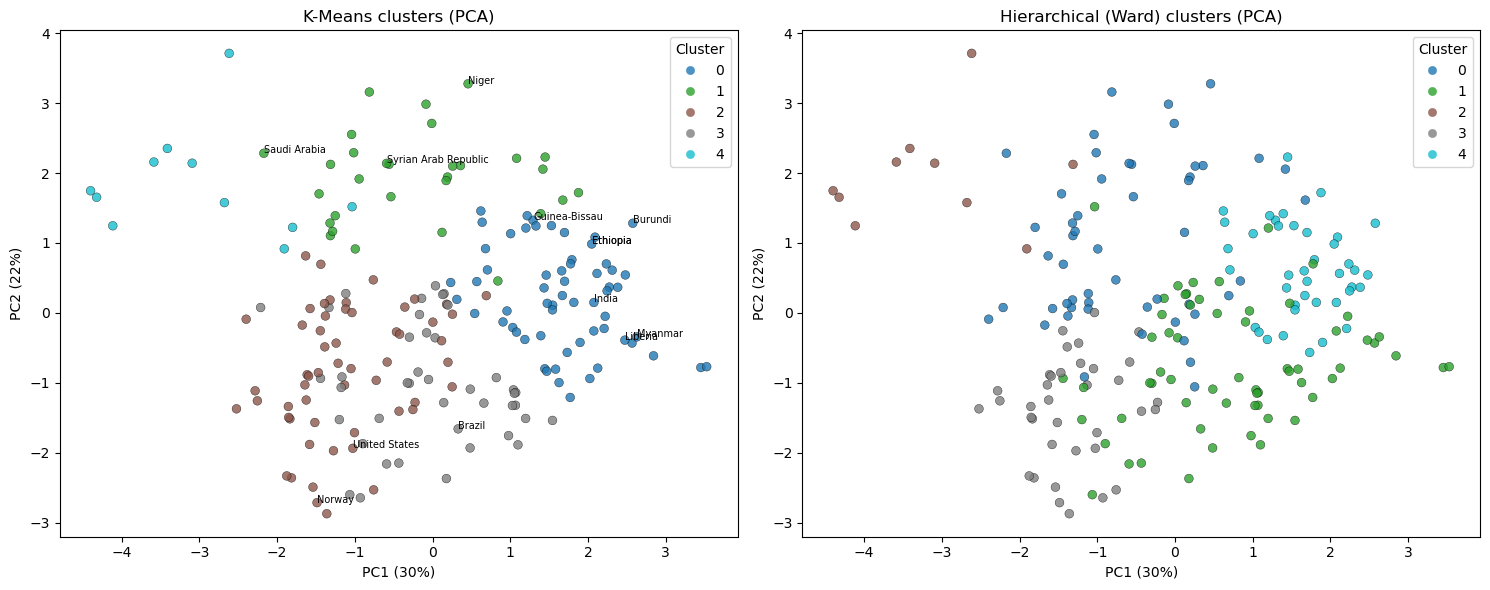


PCA loadings:
                             PC1   PC2
temp_mean                  0.27  0.32
temp_anomaly              -0.44  0.03
precip_mean                0.43 -0.46
precip_cv                 -0.34  0.38
drought_freq              -0.14  0.49
agriculture_gdp_percent    0.46  0.35
rural_population_percent   0.45  0.33
agricultural_land_percent  0.04  0.27


In [17]:
pca = PCA(n_components=2, random_state=SEED)
P = pca.fit_transform(Xs)
df["PC1"], df["PC2"] = P[:, 0], P[:, 1]
print("PCA explained variance:", pca.explained_variance_ratio_.round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, col, ttl in zip(ax, ["cluster_kmeans", "cluster_hier"], ["K-Means", "Hierarchical (Ward)"]):
    sc = a.scatter(df.PC1, df.PC2, c=df[col], cmap="tab10", s=40, alpha=.8, edgecolor="k", linewidth=.3)
    a.set_title(f"{ttl} clusters (PCA)"); a.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
    a.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
    a.legend(*sc.legend_elements(), title="Cluster")
for i in df.sort_values("agriculture_gdp_percent").index[-6:].tolist() + ["SYR", "SAU", "NOR", "IND", "BRA", "USA", "ETH"]:
    if i in df.index: ax[0].annotate(df.loc[i, "country"], (df.loc[i, "PC1"], df.loc[i, "PC2"]), fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig2_pca_clusters.png", dpi=150); plt.show()

load = pd.DataFrame(pca.components_.T, index=features, columns=["PC1", "PC2"]).round(2)
print("\nPCA loadings:\n", load)

### Cluster profiling


Cluster profiles (mean, original units):
 cluster_kmeans                  0       1        2
n_countries                 28.00   77.00    95.00
temp_mean                   23.46   11.56    25.00
temp_anomaly                 1.02    1.16     0.68
precip_mean                194.99  996.33  1666.04
precip_cv                    0.30    0.12     0.13
drought_freq                 0.27    0.13     0.14
agriculture_gdp_percent      8.83    4.69    16.42
rural_population_percent    32.22   28.73    57.17
agricultural_land_percent   36.36   40.28    36.34


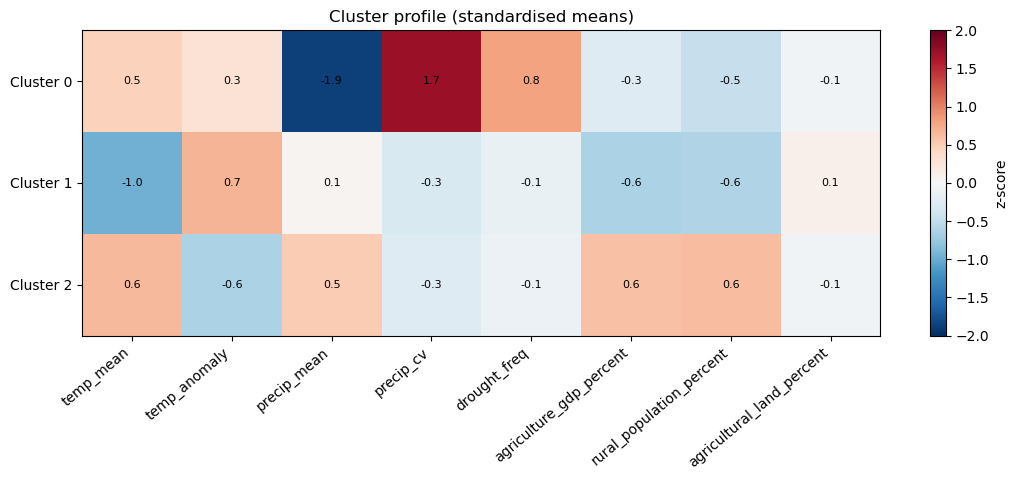


Countries per cluster:

Cluster 0 (28): Aruba, United Arab Emirates, Australia, Bahrain, Botswana, Cabo Verde, Cyprus, Djibouti, Algeria, Egypt, Iraq, Israel, Jordan, Kuwait, Libya, Morocco, Mauritania, Namibia, Niger, Oman, Palestine, State of, Qatar, Saudi Arabia, Sudan, Syrian Arab Republic ...

Cluster 1 (77): Albania, Andorra, Argentina, Armenia, Austria, Azerbaijan, Belgium, Bulgaria, Bahamas, Bosnia and Herzegovina, Belarus, Bermuda, Brazil, Canada, Switzerland, Chile, China, Cayman Islands, Czechia, Germany, Denmark, Spain, Estonia, Finland, France ...

Cluster 2 (95): Afghanistan, Angola, Antigua and Barbuda, Burundi, Benin, Burkina Faso, Bangladesh, Belize, Bolivia, Plurinational State of, Barbados, Brunei Darussalam, Bhutan, Central African Republic, Côte d'Ivoire, Cameroon, Congo, The Democratic Republic of the, Congo, Colombia, Comoros, Costa Rica, Cuba, Dominica, Dominican Republic, Ecuador, Eritrea ...


In [13]:
profile = df.groupby("cluster_kmeans")[features].mean().round(2)
profile.insert(0, "n_countries", df.groupby("cluster_kmeans").size())
print("\nCluster profiles (mean, original units):\n", profile.T.to_string())

z = pd.DataFrame(Xs, index=df.index, columns=features).groupby(df.cluster_kmeans).mean()
fig, a = plt.subplots(figsize=(11, 4 + K * .3))
im = a.imshow(z.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
a.set_xticks(range(len(features))); a.set_xticklabels(features, rotation=40, ha="right")
a.set_yticks(range(K)); a.set_yticklabels([f"Cluster {i}" for i in z.index])
for i in range(z.shape[0]):
    for j in range(z.shape[1]): a.text(j, i, f"{z.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="z-score"); a.set_title("Cluster profile (standardised means)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig3_cluster_heatmap.png", dpi=150); plt.show()

print("\nCountries per cluster:")
for c in sorted(df.cluster_kmeans.unique()):
    m = df[df.cluster_kmeans == c].country.tolist()
    print(f"\nCluster {c} ({len(m)}): " + ", ".join(m[:25]) + (" ..." if len(m) > 25 else ""))


### saving results

In [14]:
# df.to_csv(f"{OUT_DIR}/country_clusters.csv")
# res.to_csv(f"{OUT_DIR}/model_selection.csv", index=False)
# profile.to_csv(f"{OUT_DIR}/cluster_profiles.csv")
# print("\nSuccessfully saved all outputs to Google Drive under:", OUT_DIR)